In [212]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [213]:
image_path = "../dataset/raw/9pieces3.png"


In [214]:
image = cv2.imread(image_path)

In [215]:

print("Image loaded:", image is not None)
print("Image shape:", image.shape if image is not None else "Failed")

Image loaded: True
Image shape: (550, 1292, 3)


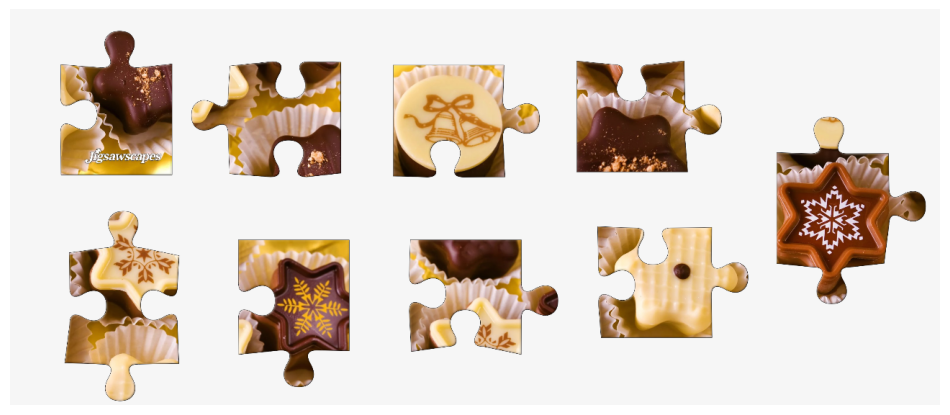

In [216]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

Convert the image to grayscale

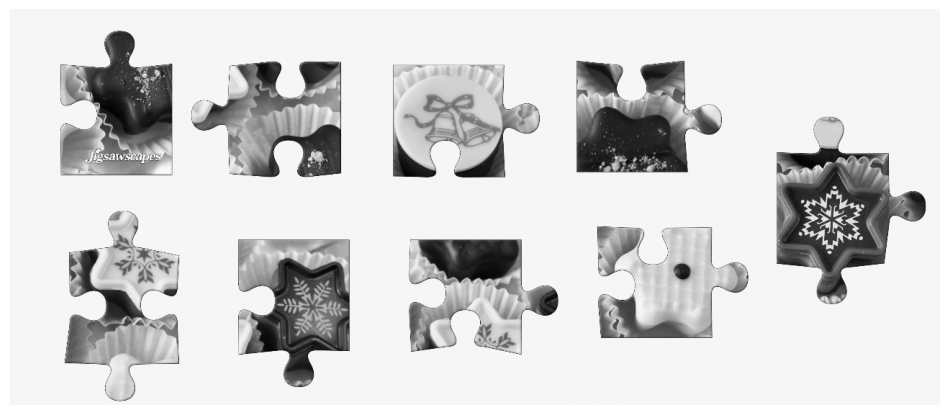

In [217]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 8))
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.show()

Remove small amounts of noise

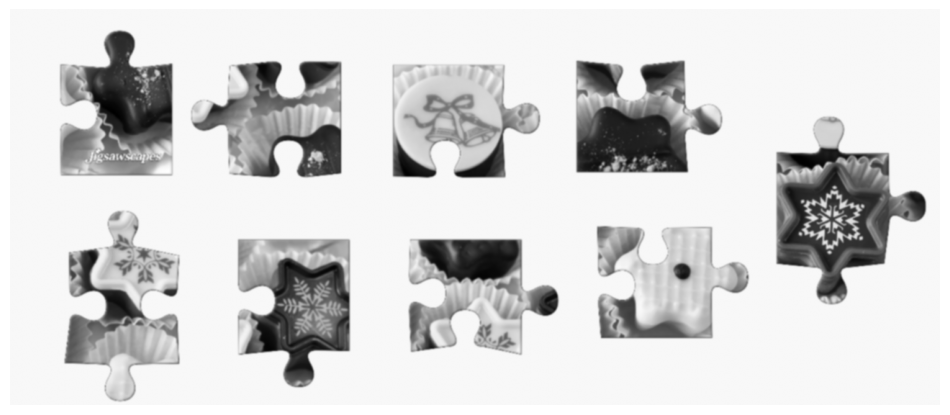

In [218]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

plt.figure(figsize=(12, 8))
plt.imshow(blurred, cmap="gray")
plt.axis("off")
plt.show()

Compare them

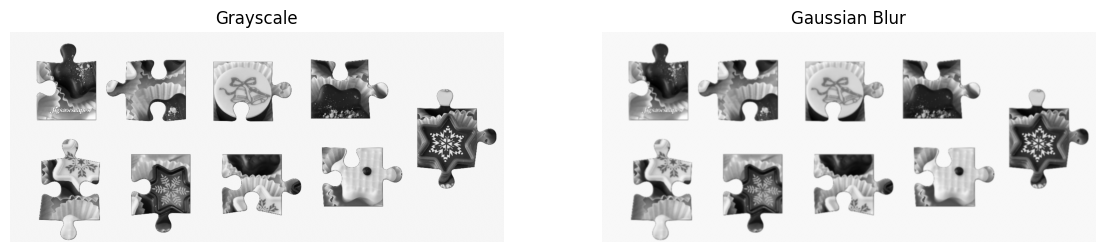

In [219]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.show()

Create a binary mask

First, let's try thresholding. Since you're using a controlled background, this is the simplest place to start.

1. Apply Otsu thresholding

In [220]:
threshold_value, binary = cv2.threshold(
    blurred,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

print("Threshold value:", threshold_value)

Threshold value: 165.0


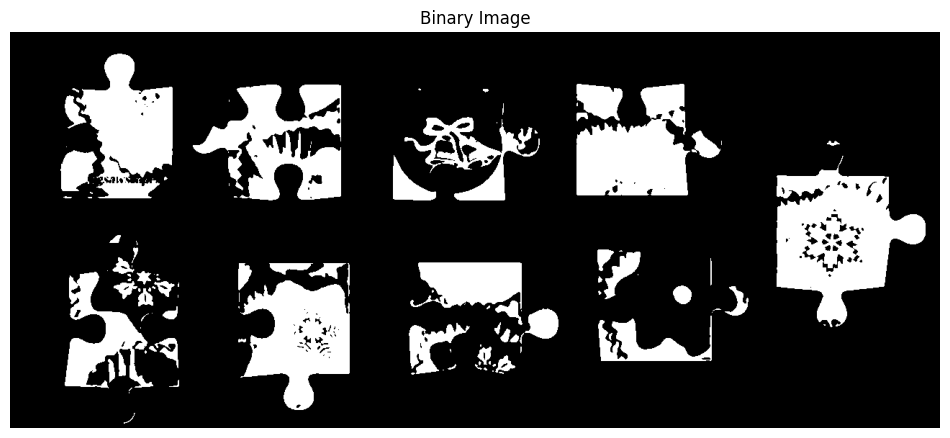

In [221]:
plt.figure(figsize=(12, 8))
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()

Morphological cleaning
morphological closing to fill small holes and gaps.

In [222]:
kernel = np.ones((5, 5), np.uint8)

cleaned = cv2.morphologyEx(
    binary,
    cv2.MORPH_CLOSE,
    kernel
)

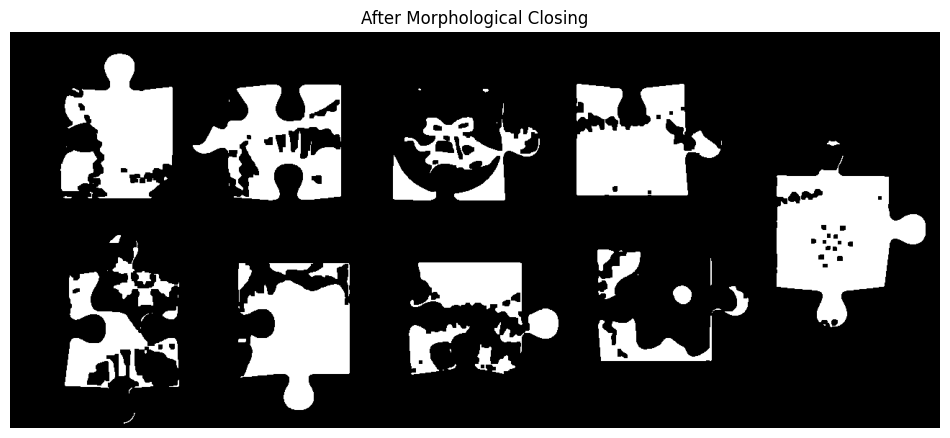

In [223]:
plt.figure(figsize=(12, 8))
plt.imshow(cleaned, cmap="gray")
plt.title("After Morphological Closing")
plt.axis("off")
plt.show()

Compare the results

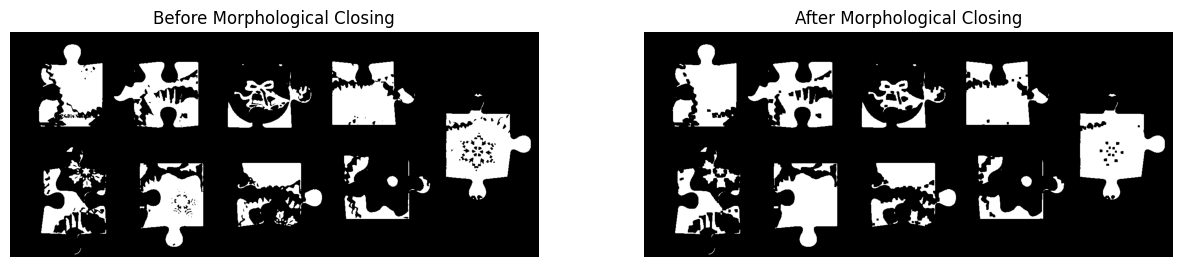

In [224]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray")
plt.title("Before Morphological Closing")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cleaned, cmap="gray")
plt.title("After Morphological Closing")
plt.axis("off")

plt.show()

Contour Detection

In [225]:
contours, hierarchy = cv2.findContours(
    cleaned,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Number of contours detected:", len(contours))

Number of contours detected: 62


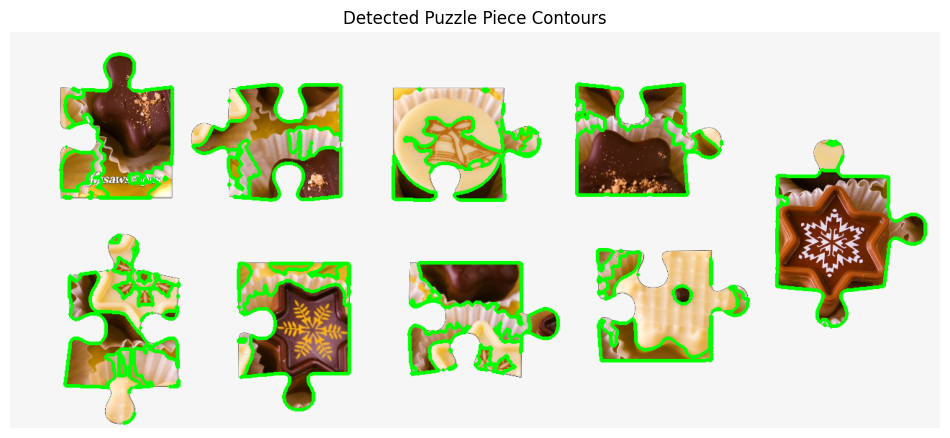

In [226]:
contour_image = image.copy()

cv2.drawContours(
    contour_image,
    contours,
    -1,
    (0, 255, 0),
    3
)

contour_image_rgb = cv2.cvtColor(
    contour_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(contour_image_rgb)
plt.title("Detected Puzzle Piece Contours")
plt.axis("off")
plt.show()

In [227]:
for i, contour in enumerate(contours):
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    print(
        f"Piece {i+1}: "
        f"Area = {area:.2f}, "
        f"Perimeter = {perimeter:.2f}"
    )

Piece 1: Area = 9.50, Perimeter = 46.87
Piece 2: Area = 3.50, Perimeter = 17.90
Piece 3: Area = 16.50, Perimeter = 41.07
Piece 4: Area = 0.00, Perimeter = 2.00
Piece 5: Area = 20.50, Perimeter = 29.56
Piece 6: Area = 7.00, Perimeter = 10.83
Piece 7: Area = 2.00, Perimeter = 8.83
Piece 8: Area = 817.00, Perimeter = 226.37
Piece 9: Area = 39.00, Perimeter = 26.83
Piece 10: Area = 286.00, Perimeter = 134.08
Piece 11: Area = 0.00, Perimeter = 2.00
Piece 12: Area = 1.50, Perimeter = 5.41
Piece 13: Area = 2456.50, Perimeter = 349.87
Piece 14: Area = 55.50, Perimeter = 41.56
Piece 15: Area = 4242.00, Perimeter = 613.91
Piece 16: Area = 7.50, Perimeter = 31.21
Piece 17: Area = 0.00, Perimeter = 0.00
Piece 18: Area = 0.00, Perimeter = 0.00
Piece 19: Area = 5.00, Perimeter = 24.49
Piece 20: Area = 1360.50, Perimeter = 152.81
Piece 21: Area = 1.50, Perimeter = 5.41
Piece 22: Area = 182.00, Perimeter = 64.63
Piece 23: Area = 0.00, Perimeter = 6.00
Piece 24: Area = 506.50, Perimeter = 142.81
Piece 

Analyse each contour

In [228]:
contours = sorted(
    contours,
    key=cv2.contourArea,
    reverse=True
)

print("Number of contours:", len(contours))

Number of contours: 62


In [229]:
for i, contour in enumerate(contours):
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    x, y, w, h = cv2.boundingRect(contour)

    print(f"\nPiece {i+1}")
    print(f"Area: {area:.2f}")
    print(f"Perimeter: {perimeter:.2f}")
    print(f"Width: {w}")
    print(f"Height: {h}")


Piece 1
Area: 27340.50
Perimeter: 926.17
Width: 207
Height: 238

Piece 2
Area: 19967.50
Perimeter: 1136.88
Width: 200
Height: 155

Piece 3
Area: 17255.50
Perimeter: 1480.59
Width: 206
Height: 161

Piece 4
Area: 16834.00
Perimeter: 794.07
Width: 152
Height: 180

Piece 5
Area: 16792.00
Perimeter: 936.50
Width: 150
Height: 201

Piece 6
Area: 9394.00
Perimeter: 1044.78
Width: 158
Height: 162

Piece 7
Area: 8084.00
Perimeter: 581.56
Width: 156
Height: 87

Piece 8
Area: 7434.00
Perimeter: 1060.81
Width: 188
Height: 116

Piece 9
Area: 4242.00
Perimeter: 613.91
Width: 158
Height: 63

Piece 10
Area: 2456.50
Perimeter: 349.87
Width: 85
Height: 72

Piece 11
Area: 1993.50
Perimeter: 198.47
Width: 51
Height: 57

Piece 12
Area: 1633.00
Perimeter: 505.71
Width: 93
Height: 91

Piece 13
Area: 1569.00
Perimeter: 215.88
Width: 60
Height: 63

Piece 14
Area: 1360.50
Perimeter: 152.81
Width: 47
Height: 42

Piece 15
Area: 1311.00
Perimeter: 260.99
Width: 59
Height: 66

Piece 16
Area: 817.00
Perimeter: 226.3

Calculate shape characteristics

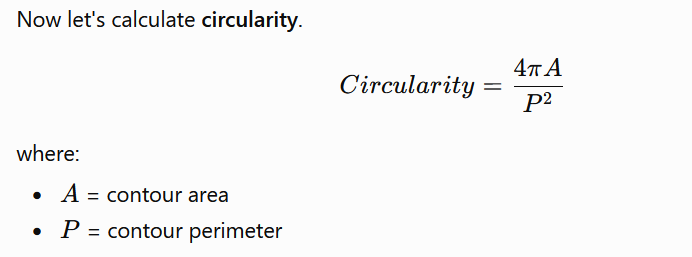

In [230]:
import math

for i, contour in enumerate(contours):

    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    if perimeter != 0:
        circularity = (4 * math.pi * area) / (perimeter ** 2)
    else:
        circularity = 0

    print(
        f"Piece {i+1}: "
        f"Area={area:.2f}, "
        f"Perimeter={perimeter:.2f}, "
        f"Circularity={circularity:.3f}"
    )

Piece 1: Area=27340.50, Perimeter=926.17, Circularity=0.401
Piece 2: Area=19967.50, Perimeter=1136.88, Circularity=0.194
Piece 3: Area=17255.50, Perimeter=1480.59, Circularity=0.099
Piece 4: Area=16834.00, Perimeter=794.07, Circularity=0.335
Piece 5: Area=16792.00, Perimeter=936.50, Circularity=0.241
Piece 6: Area=9394.00, Perimeter=1044.78, Circularity=0.108
Piece 7: Area=8084.00, Perimeter=581.56, Circularity=0.300
Piece 8: Area=7434.00, Perimeter=1060.81, Circularity=0.083
Piece 9: Area=4242.00, Perimeter=613.91, Circularity=0.141
Piece 10: Area=2456.50, Perimeter=349.87, Circularity=0.252
Piece 11: Area=1993.50, Perimeter=198.47, Circularity=0.636
Piece 12: Area=1633.00, Perimeter=505.71, Circularity=0.080
Piece 13: Area=1569.00, Perimeter=215.88, Circularity=0.423
Piece 14: Area=1360.50, Perimeter=152.81, Circularity=0.732
Piece 15: Area=1311.00, Perimeter=260.99, Circularity=0.242
Piece 16: Area=817.00, Perimeter=226.37, Circularity=0.200
Piece 17: Area=544.50, Perimeter=238.81, 

Visualise one contour

In [231]:
piece = contours[0]

contour_points = piece.reshape(-1, 2)

print("Number of contour points:", len(contour_points))

Number of contour points: 271


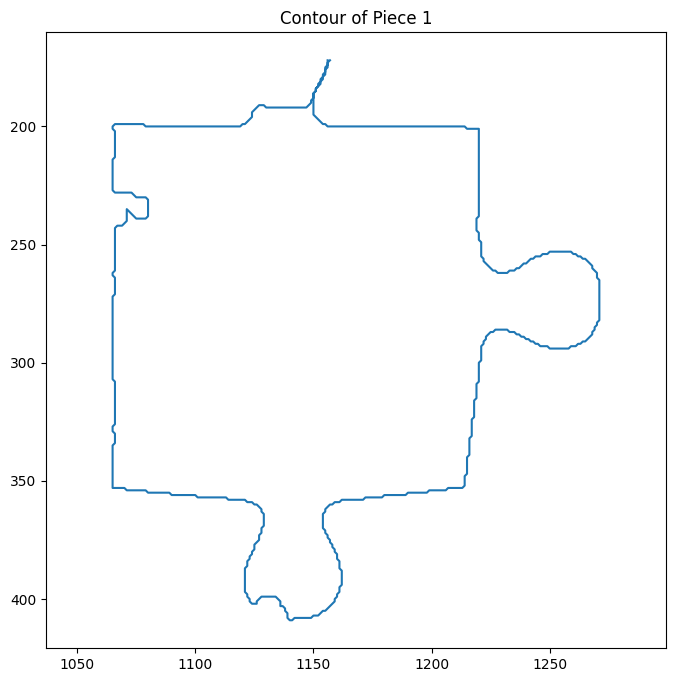

In [232]:
plt.figure(figsize=(8, 8))

plt.plot(
    contour_points[:, 0],
    contour_points[:, 1]
)

plt.gca().invert_yaxis()
plt.axis("equal")
plt.title("Contour of Piece 1")
plt.show()

Approximate the contour

In [233]:
perimeter = cv2.arcLength(piece, True)

epsilon = 0.01 * perimeter

approx = cv2.approxPolyDP(
    piece,
    epsilon,
    True
)

print("Original contour points:", len(piece))
print("Approximated points:", len(approx))

Original contour points: 271
Approximated points: 20


In [234]:
for factor in [0.005, 0.01, 0.02, 0.03]:

    epsilon = factor * perimeter

    approx = cv2.approxPolyDP(
        piece,
        epsilon,
        True
    )

    print(
        f"Epsilon = {factor:.3f} "
        f"→ Points = {len(approx)}"
    )

Epsilon = 0.005 → Points = 28
Epsilon = 0.010 → Points = 20
Epsilon = 0.020 → Points = 13
Epsilon = 0.030 → Points = 9


Get the bounding box

In [235]:
piece = contours[0]

x, y, w, h = cv2.boundingRect(piece)

print("x:", x)
print("y:", y)
print("width:", w)
print("height:", h)

x: 1065
y: 172
width: 207
height: 238


In [236]:
cx = x + w / 2
cy = y + h / 2

print("Centre:", cx, cy)

Centre: 1168.5 291.0


Divide the contour into four regions

In [237]:
points = piece.reshape(-1, 2)

top_points = []
bottom_points = []
left_points = []
right_points = []

for px, py in points:

    if py < cy and abs(px - cx) > abs(py - cy):
        top_points.append((px, py))

    elif py > cy and abs(px - cx) > abs(py - cy):
        bottom_points.append((px, py))

    elif px < cx:
        left_points.append((px, py))

    else:
        right_points.append((px, py))

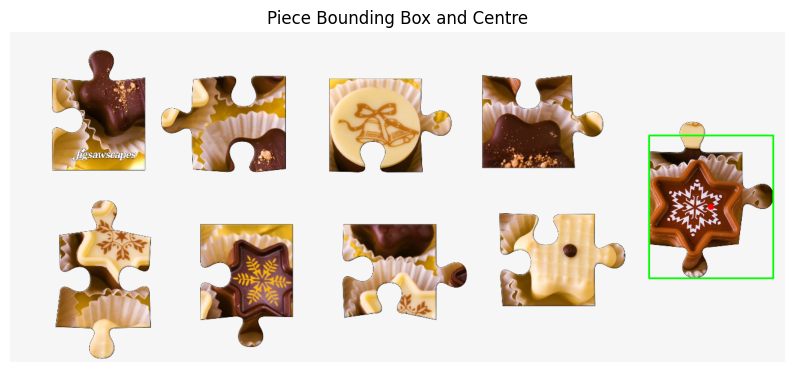

In [238]:
image_test = image.copy()

cv2.rectangle(
    image_test,
    (x, y),
    (x + w, y + h),
    (0, 255, 0),
    2
)

cv2.circle(
    image_test,
    (int(cx), int(cy)),
    5,
    (0, 0, 255),
    -1
)

image_test_rgb = cv2.cvtColor(
    image_test,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(10, 8))
plt.imshow(image_test_rgb)
plt.title("Piece Bounding Box and Centre")
plt.axis("off")
plt.show()

In [239]:
angles = []

for px, py in points:

    dx = px - cx
    dy = py - cy

    angle = np.arctan2(dy, dx)

    angles.append(angle)

Plot the contour as a radial shape

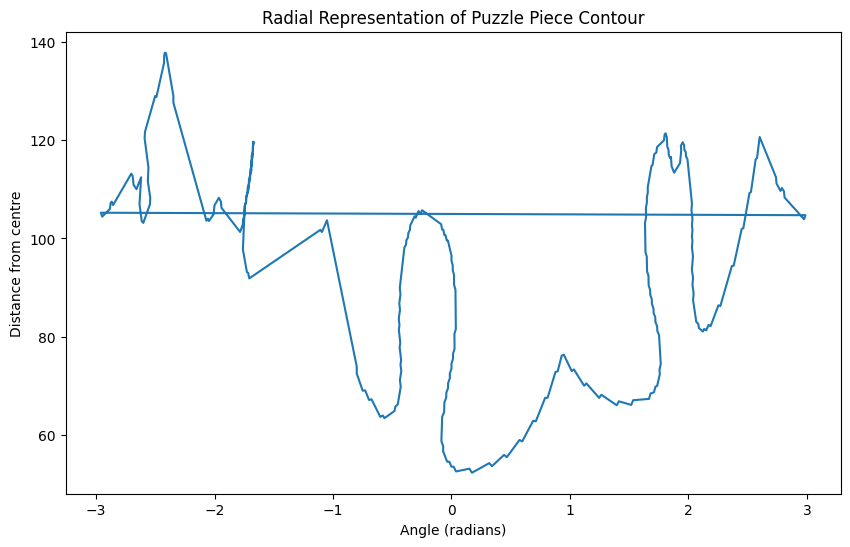

In [240]:
dx = points[:, 0] - cx
dy = points[:, 1] - cy

r = np.sqrt(dx**2 + dy**2)
theta = np.arctan2(dy, dx)

plt.figure(figsize=(10, 6))

plt.plot(theta, r)

plt.xlabel("Angle (radians)")
plt.ylabel("Distance from centre")
plt.title("Radial Representation of Puzzle Piece Contour")
plt.show()

Extract the four sides properly

In [241]:
piece = contours[0]
points = piece.reshape(-1, 2)

x, y, w, h = cv2.boundingRect(piece)

left_boundary = x + 0.25 * w
right_boundary = x + 0.75 * w

top_boundary = y + 0.25 * h
bottom_boundary = y + 0.75 * h

In [242]:
top = []
right = []
bottom = []
left = []

for px, py in points:

    if py <= top_boundary:
        top.append((px, py))

    elif py >= bottom_boundary:
        bottom.append((px, py))

    elif px <= left_boundary:
        left.append((px, py))

    elif px >= right_boundary:
        right.append((px, py))

In [243]:
print("Top:", len(top))
print("Right:", len(right))
print("Bottom:", len(bottom))
print("Left:", len(left))

Top: 58
Right: 72
Bottom: 101
Left: 22


Visualise the four sides

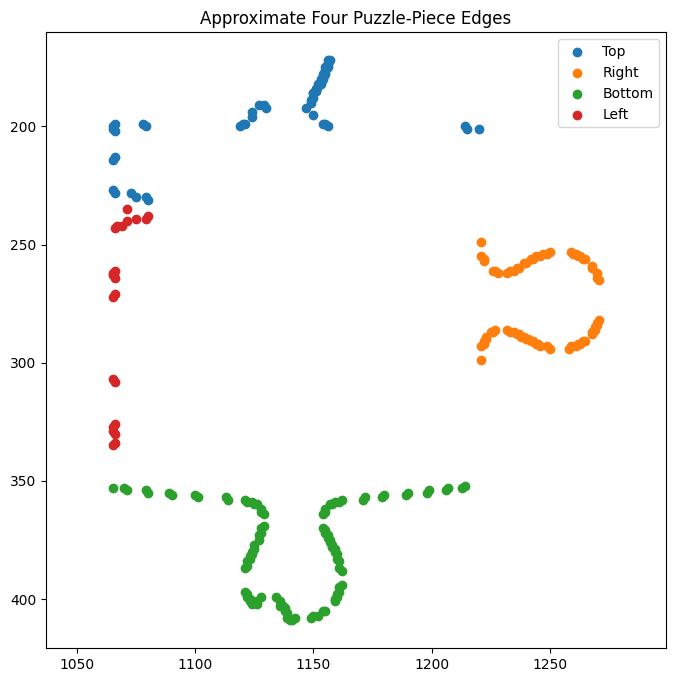

In [244]:
plt.figure(figsize=(8, 8))

if top:
    top = np.array(top)
    plt.scatter(top[:, 0], top[:, 1], label="Top")

if right:
    right = np.array(right)
    plt.scatter(right[:, 0], right[:, 1], label="Right")

if bottom:
    bottom = np.array(bottom)
    plt.scatter(bottom[:, 0], bottom[:, 1], label="Bottom")

if left:
    left = np.array(left)
    plt.scatter(left[:, 0], left[:, 1], label="Left")

plt.gca().invert_yaxis()
plt.axis("equal")
plt.legend()
plt.title("Approximate Four Puzzle-Piece Edges")
plt.show()

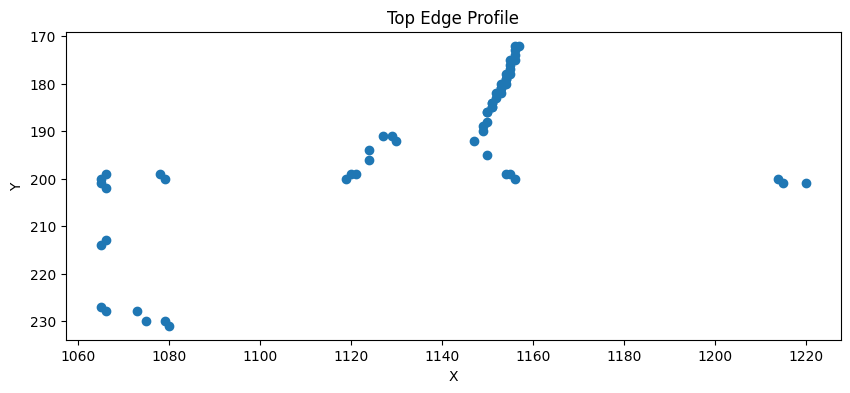

In [245]:
top = np.array(top)

x_top = top[:, 0]
y_top = top[:, 1]

plt.figure(figsize=(10, 4))
plt.scatter(x_top, y_top)
plt.gca().invert_yaxis()
plt.title("Top Edge Profile")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

In [246]:
top = np.array(top, dtype=np.float32)

x_values = top[:, 0]
y_values = top[:, 1]

coefficients = np.polyfit(x_values, y_values, 1)

slope = coefficients[0]
intercept = coefficients[1]

print("Slope:", slope)
print("Intercept:", intercept)

Slope: -0.26278995077486267
Intercept: 490.76755839640407


In [247]:
y_line = slope * x_values + intercept

deviation = y_values - y_line

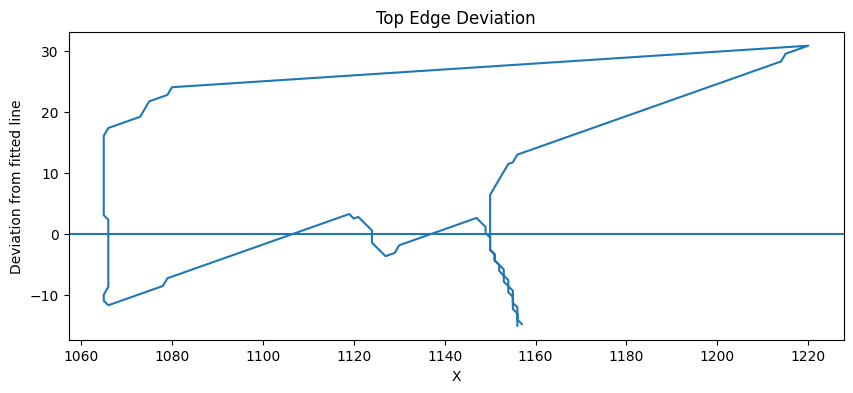

In [248]:
plt.figure(figsize=(10, 4))

plt.plot(x_values, deviation)

plt.axhline(0)

plt.title("Top Edge Deviation")
plt.xlabel("X")
plt.ylabel("Deviation from fitted line")

plt.show()

Extract all four edge profiles

In [249]:
piece = contours[0]
points = piece.reshape(-1, 2)

x, y, w, h = cv2.boundingRect(piece)

xmin = x
xmax = x + w
ymin = y
ymax = y + h

In [250]:
margin_x = 0.15 * w
margin_y = 0.15 * h

top = []
bottom = []
left = []
right = []

for px, py in points:

    # Top edge
    if (
        py < ymin + 0.30 * h
        and xmin + margin_x < px < xmax - margin_x
    ):
        top.append((px, py))

    # Bottom edge
    elif (
        py > ymin + 0.70 * h
        and xmin + margin_x < px < xmax - margin_x
    ):
        bottom.append((px, py))

    # Left edge
    elif (
        px < xmin + 0.30 * w
        and ymin + margin_y < py < ymax - margin_y
    ):
        left.append((px, py))

    # Right edge
    elif (
        px > xmin + 0.70 * w
        and ymin + margin_y < py < ymax - margin_y
    ):
        right.append((px, py))

In [251]:
print("Top:", len(top))
print("Right:", len(right))
print("Bottom:", len(bottom))
print("Left:", len(left))

Top: 46
Right: 84
Bottom: 98
Left: 37


Visualise all four edges

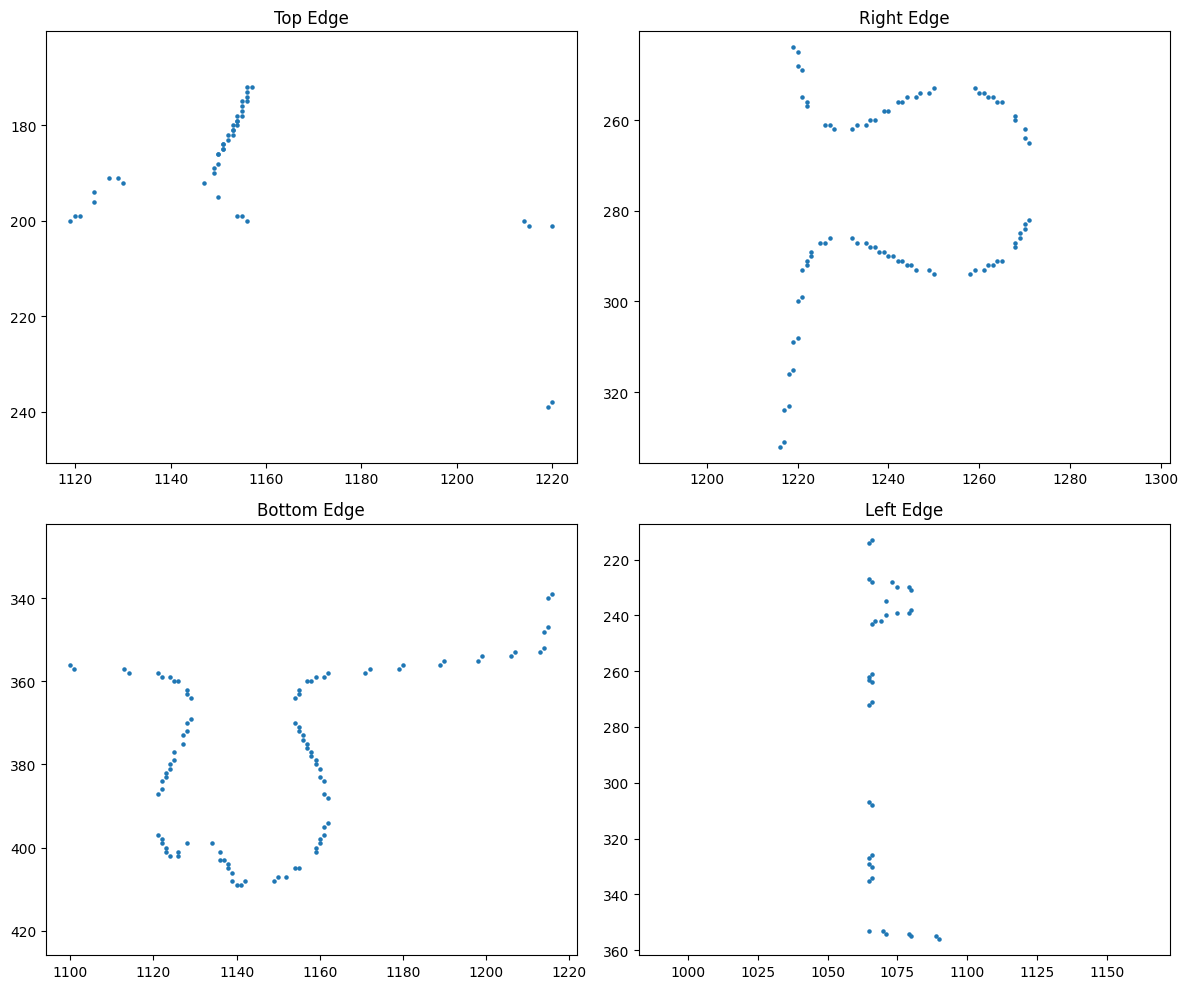

In [252]:
plt.figure(figsize=(12, 10))

edges = {
    "Top": np.array(top),
    "Right": np.array(right),
    "Bottom": np.array(bottom),
    "Left": np.array(left)
}

for i, (name, edge) in enumerate(edges.items()):

    plt.subplot(2, 2, i + 1)

    if len(edge) > 0:
        plt.scatter(edge[:, 0], edge[:, 1], s=5)

    plt.gca().invert_yaxis()
    plt.axis("equal")
    plt.title(f"{name} Edge")

plt.tight_layout()
plt.show()

Create a reusable edge-profile function

In [253]:
def calculate_edge_profile(edge):

    edge = np.array(edge, dtype=np.float32)

    if len(edge) < 5:
        return None, None

    # Sort points along the dominant direction
    x_values = edge[:, 0]
    y_values = edge[:, 1]

    if np.ptp(x_values) >= np.ptp(y_values):

        order = np.argsort(x_values)
        coordinate = x_values[order]
        values = y_values[order]

    else:

        order = np.argsort(y_values)
        coordinate = y_values[order]
        values = x_values[order]

    # Fit a straight reference line
    coefficients = np.polyfit(
        coordinate,
        values,
        1
    )

    fitted = (
        coefficients[0] * coordinate
        + coefficients[1]
    )

    deviation = values - fitted

    return coordinate, deviation

In [254]:
profiles = {}

for name, edge in edges.items():

    coordinate, deviation = calculate_edge_profile(edge)

    profiles[name] = (
        coordinate,
        deviation
    )

Plot the deviation profiles

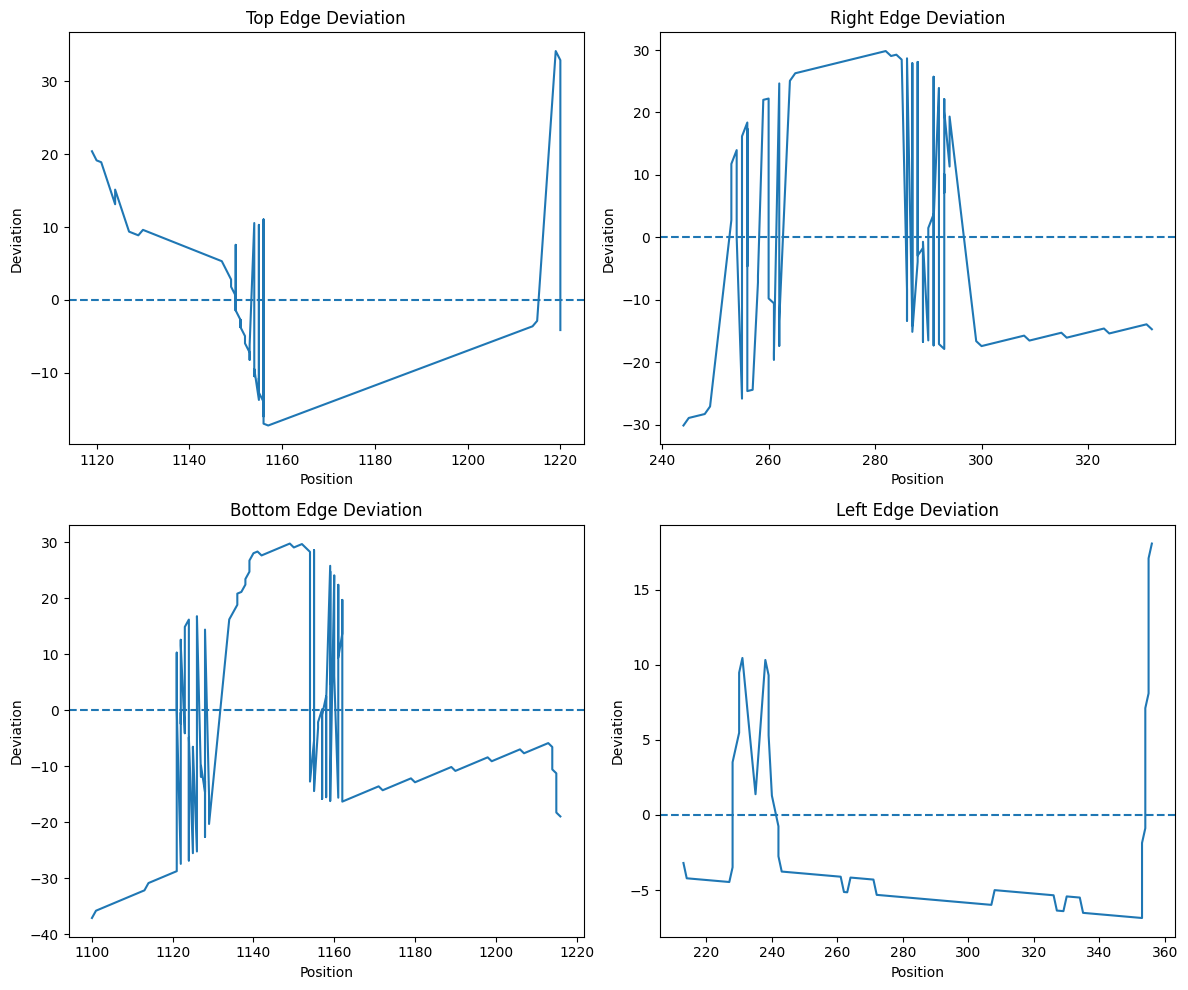

In [255]:
plt.figure(figsize=(12, 10))

for i, (name, profile) in enumerate(profiles.items()):

    coordinate, deviation = profile

    plt.subplot(2, 2, i + 1)

    if coordinate is not None:
        plt.plot(coordinate, deviation)

    plt.axhline(0, linestyle="--")
    plt.title(f"{name} Edge Deviation")
    plt.xlabel("Position")
    plt.ylabel("Deviation")

plt.tight_layout()
plt.show()

Calculate an edge "strength"
A simple first feature is:

D=mean(∣deviation∣)

In [256]:
for name, profile in profiles.items():

    coordinate, deviation = profile

    if deviation is not None:

        mean_deviation = np.mean(
            np.abs(deviation)
        )

        max_deviation = np.max(
            np.abs(deviation)
        )

        print(
            f"{name}: "
            f"Mean deviation = {mean_deviation:.2f}, "
            f"Max deviation = {max_deviation:.2f}"
        )

Top: Mean deviation = 10.07, Max deviation = 34.13
Right: Mean deviation = 15.21, Max deviation = 30.12
Bottom: Mean deviation = 15.38, Max deviation = 37.07
Left: Mean deviation = 5.78, Max deviation = 18.08


Normalise every edge

Create a normalisation function

In [257]:
def normalise_edge(edge, side):

    edge = np.array(edge, dtype=np.float32)

    if len(edge) < 5:
        return None, None

    # Top and bottom primarily vary along X
    if side in ["Top", "Bottom"]:

        order = np.argsort(edge[:, 0])

        position = edge[order, 0]
        deviation = edge[order, 1]

    # Left and right primarily vary along Y
    else:

        order = np.argsort(edge[:, 1])

        position = edge[order, 1]
        deviation = edge[order, 0]

    # Fit straight reference line
    coefficients = np.polyfit(
        position,
        deviation,
        1
    )

    fitted = (
        coefficients[0] * position
        + coefficients[1]
    )

    deviation = deviation - fitted

    # Normalise position to 0 → 1
    position = (
        position - position.min()
    ) / (
        position.max() - position.min()
    )

    return position, deviation

In [258]:
normalised_profiles = {}

for name, edge in edges.items():

    position, deviation = normalise_edge(
        edge,
        name
    )

    normalised_profiles[name] = (
        position,
        deviation
    )

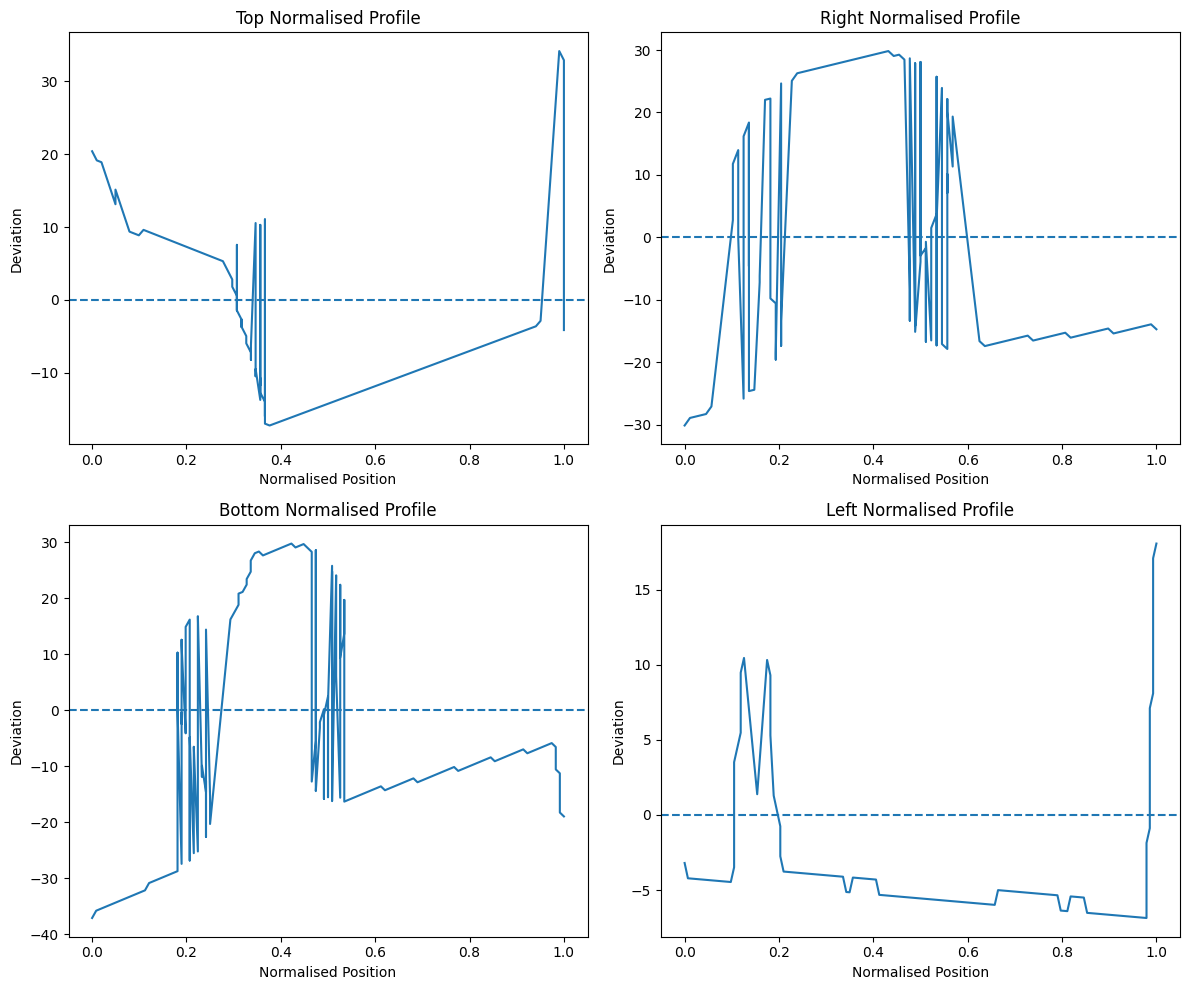

In [259]:
plt.figure(figsize=(12, 10))

for i, (name, profile) in enumerate(
    normalised_profiles.items()
):

    position, deviation = profile

    plt.subplot(2, 2, i + 1)

    if position is not None:
        plt.plot(position, deviation)

    plt.axhline(0, linestyle="--")

    plt.title(f"{name} Normalised Profile")
    plt.xlabel("Normalised Position")
    plt.ylabel("Deviation")

plt.tight_layout()
plt.show()

Resample the curves

In [260]:
def resample_profile(position, deviation, n=100):

    if position is None:
        return None

    new_position = np.linspace(0, 1, n)

    new_deviation = np.interp(
        new_position,
        position,
        deviation
    )

    return new_position, new_deviation

In [261]:
resampled_profiles = {}

for name, profile in normalised_profiles.items():

    position, deviation = profile

    resampled_profiles[name] = resample_profile(
        position,
        deviation,
        n=100
    )

Detect whether an edge is flat

In [262]:
def edge_features(profile):

    if profile is None:
        return None

    position, deviation = profile

    mean_abs = np.mean(
        np.abs(deviation)
    )

    max_abs = np.max(
        np.abs(deviation)
    )

    std = np.std(deviation)

    return {
        "mean_deviation": mean_abs,
        "max_deviation": max_abs,
        "std_deviation": std
    }

In [263]:
for name, profile in resampled_profiles.items():

    features = edge_features(profile)

    print(name)
    print(features)

Top
{'mean_deviation': np.float64(10.195879552305493), 'max_deviation': np.float64(33.94323626033202), 'std_deviation': np.float64(11.105472648119445)}
Right
{'mean_deviation': np.float64(17.994592853813405), 'max_deviation': np.float64(30.116610417970605), 'std_deviation': np.float64(19.803081542203422)}
Bottom
{'mean_deviation': np.float64(17.637853615089288), 'max_deviation': np.float64(37.06874681925831), 'std_deviation': np.float64(19.106300004594196)}
Left
{'mean_deviation': np.float64(5.346277710787417), 'max_deviation': np.float64(18.081731506283177), 'std_deviation': np.float64(4.273506142339251)}


Visualise the four normalised curves together

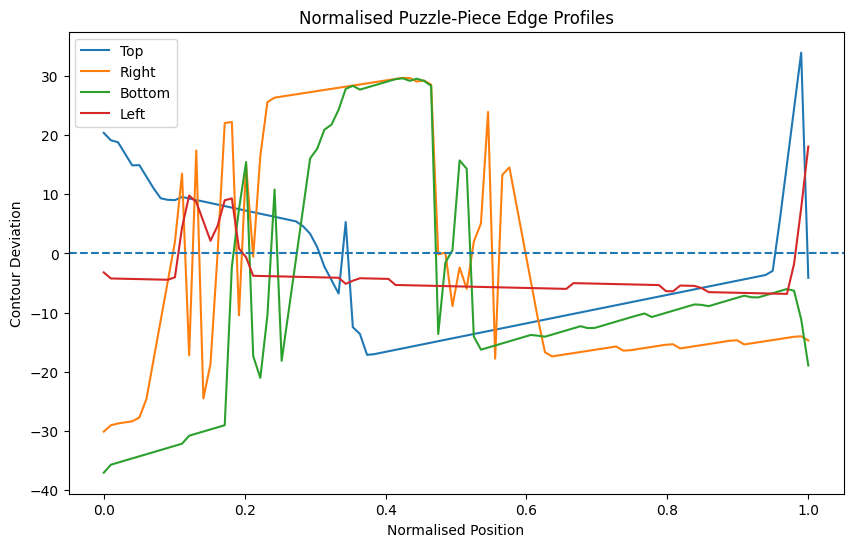

In [264]:
plt.figure(figsize=(10, 6))

for name, profile in resampled_profiles.items():

    if profile is not None:

        position, deviation = profile

        plt.plot(
            position,
            deviation,
            label=name
        )

plt.axhline(0, linestyle="--")

plt.xlabel("Normalised Position")
plt.ylabel("Contour Deviation")

plt.title("Normalised Puzzle-Piece Edge Profiles")

plt.legend()
plt.show()

Calculate outward deviation

In [265]:
def get_edge_profile(edge, piece_center, side, n=100):

    edge = np.array(edge, dtype=np.float32)

    if len(edge) < 5:
        return None

    # Fit a straight line to the edge
    [vx, vy, x0, y0] = cv2.fitLine(
        edge,
        cv2.DIST_L2,
        0,
        0.01,
        0.01
    )

    vx = float(vx)
    vy = float(vy)
    x0 = float(x0)
    y0 = float(y0)

    # Tangent vector
    tangent = np.array([vx, vy])

    # Normal vector
    normal = np.array([-vy, vx])

    # Edge centre
    edge_center = np.mean(edge, axis=0)

    # Vector from piece centre to edge
    outward = edge_center - np.array(piece_center)

    # Make normal point outward
    if np.dot(normal, outward) < 0:
        normal = -normal

    # Calculate signed distance from fitted line
    deviations = []

    positions = []

    for point in edge:

        point_vector = point - np.array([x0, y0])

        distance = np.dot(
            point_vector,
            normal
        )

        # Position along edge
        position = np.dot(
            point_vector,
            tangent
        )

        deviations.append(distance)
        positions.append(position)

    positions = np.array(positions)
    deviations = np.array(deviations)

    # Sort along the edge
    order = np.argsort(positions)

    positions = positions[order]
    deviations = deviations[order]

    # Normalise position to 0 → 1
    positions = (
        positions - positions.min()
    ) / (
        positions.max() - positions.min()
    )

    # Resample to fixed length
    new_positions = np.linspace(0, 1, n)

    new_deviations = np.interp(
        new_positions,
        positions,
        deviations
    )

    return new_positions, new_deviations

Get the centre of your piece

In [266]:
piece_center = (
    x + w / 2,
    y + h / 2
)

print("Piece centre:", piece_center)

Piece centre: (1168.5, 291.0)


In [267]:
edge_profiles = {}

for name, edge in edges.items():

    profile = get_edge_profile(
        edge,
        piece_center,
        name
    )

    edge_profiles[name] = profile

C:\Users\HP\AppData\Local\Temp\ipykernel_252\1709512756.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  vx = float(vx)
C:\Users\HP\AppData\Local\Temp\ipykernel_252\1709512756.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  vy = float(vy)
C:\Users\HP\AppData\Local\Temp\ipykernel_252\1709512756.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  x0 = float(x0)
C:\Users\HP\AppData\Local\Temp\ipykernel_252\1709512756.py:20: DeprecationWarning: Conversion of 

Plot the new profiles

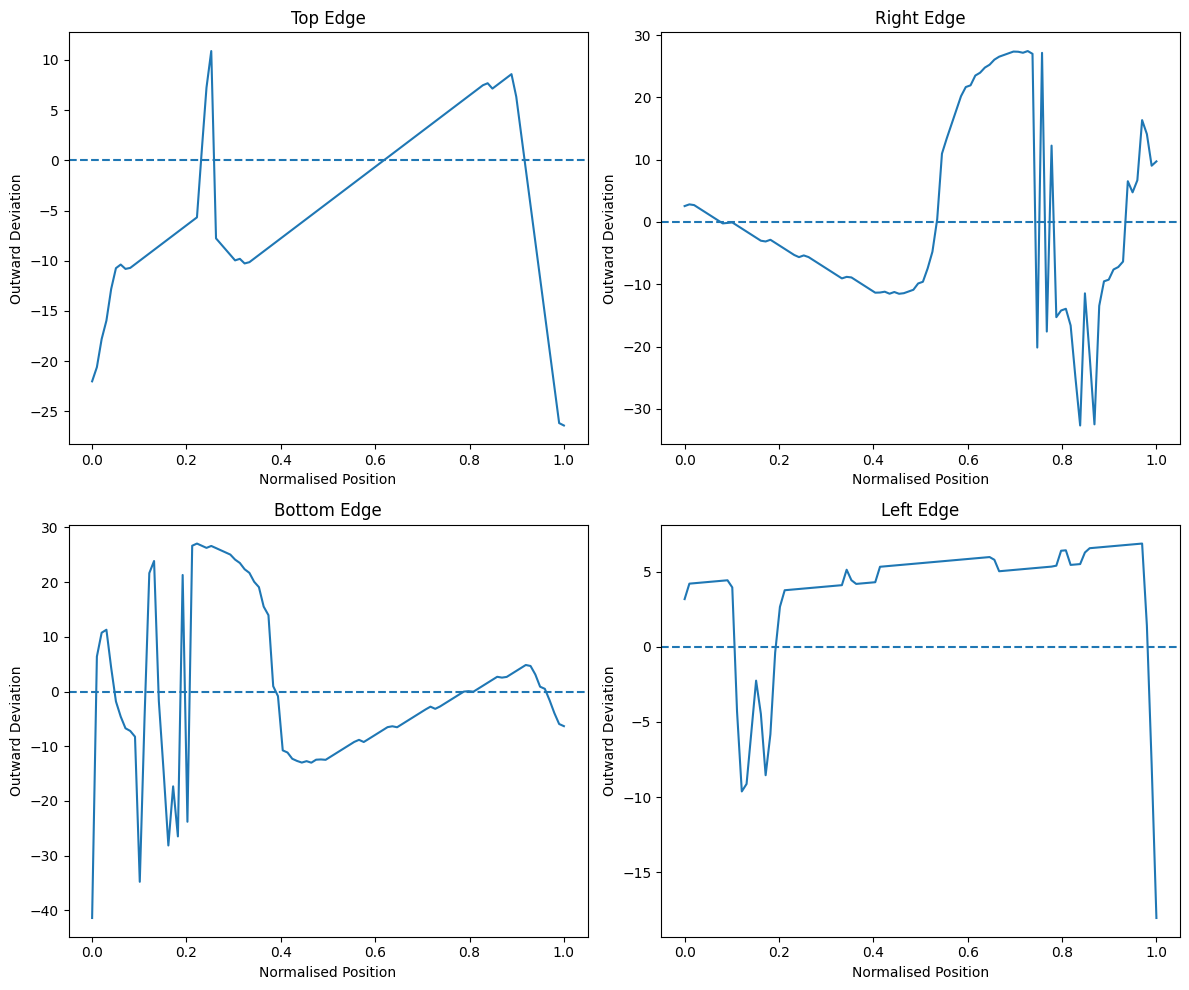

In [268]:
plt.figure(figsize=(12, 10))

for i, (name, profile) in enumerate(
    edge_profiles.items()
):

    plt.subplot(2, 2, i + 1)

    if profile is not None:

        position, deviation = profile

        plt.plot(
            position,
            deviation
        )

        plt.axhline(
            0,
            linestyle="--"
        )

    plt.title(f"{name} Edge")
    plt.xlabel("Normalised Position")
    plt.ylabel("Outward Deviation")

plt.tight_layout()
plt.show()

Create a simple classifier

In [269]:
def classify_edge(profile):

    if profile is None:
        return "UNKNOWN"

    position, deviation = profile

    mean = np.mean(deviation)
    max_value = np.max(deviation)
    min_value = np.min(deviation)

    threshold = 3.0

    if max_value < threshold and abs(min_value) < threshold:
        return "FLAT"

    if mean > threshold:
        return "TAB"

    if mean < -threshold:
        return "GAP"

    return "NON-FLAT"

In [270]:
for name, profile in edge_profiles.items():

    classification = classify_edge(profile)

    print(
        f"{name}: {classification}"
    )

Top: GAP
Right: NON-FLAT
Bottom: NON-FLAT
Left: TAB


Represent the whole piece

In [271]:
piece_type = {}

for name, profile in edge_profiles.items():

    piece_type[name] = classify_edge(profile)

print(piece_type)

{'Top': 'GAP', 'Right': 'NON-FLAT', 'Bottom': 'NON-FLAT', 'Left': 'TAB'}


Get two candidate edges

In [272]:
for i, contour in enumerate(contours):
    x, y, w, h = cv2.boundingRect(contour)

    print(
        f"Piece {i}: "
        f"x={x}, y={y}, w={w}, h={h}"
    )

Piece 0: x=1065, y=172, w=207, h=238
Piece 1: x=787, y=72, w=200, h=155
Piece 2: x=254, y=73, w=206, h=161
Piece 3: x=320, y=345, w=152, h=180
Piece 4: x=76, y=30, w=150, h=201
Piece 5: x=76, y=333, w=158, h=162
Piece 6: x=556, y=320, w=156, h=87
Piece 7: x=548, y=118, w=188, h=116
Piece 8: x=817, y=394, w=158, h=63
Piece 9: x=554, y=404, w=85, h=72
Piece 10: x=70, y=164, w=51, h=57
Piece 11: x=142, y=290, w=93, h=91
Piece 12: x=532, y=171, w=60, h=63
Piece 13: x=715, y=384, w=47, h=42
Piece 14: x=817, y=305, w=59, h=66
Piece 15: x=646, y=434, w=56, h=41
Piece 16: x=415, y=321, w=57, h=46
Piece 17: x=360, y=321, w=61, h=16
Piece 18: x=993, y=353, w=33, h=41
Piece 19: x=921, y=352, w=26, h=26
Piece 20: x=317, y=321, w=19, h=54
Piece 21: x=816, y=302, w=23, h=30
Piece 22: x=681, y=412, w=33, h=34
Piece 23: x=176, y=332, w=20, h=19
Piece 24: x=212, y=381, w=21, h=18
Piece 25: x=138, y=282, w=16, h=11
Piece 26: x=1135, y=151, w=18, h=7
Piece 27: x=673, y=403, w=9, h=17
Piece 28: x=317, y=4

In [273]:
piece_A = contours[0]
piece_B = contours[1]

In [274]:
def split_contour_into_edges(piece):

    points = piece.reshape(-1, 2)

    x, y, w, h = cv2.boundingRect(piece)

    xmin = x
    xmax = x + w
    ymin = y
    ymax = y + h

    bbox_corners = np.array([
        [xmin, ymin],
        [xmax, ymin],
        [xmax, ymax],
        [xmin, ymax]
    ])

    corner_indices = []

    for corner in bbox_corners:

        distances = np.linalg.norm(
            points - corner,
            axis=1
        )

        index = np.argmin(distances)

        corner_indices.append(index)

    corner_indices = sorted(corner_indices)

    edges = []

    for i in range(4):

        start = corner_indices[i]

        if i == 3:
            end = corner_indices[0] + len(points)
        else:
            end = corner_indices[i + 1]

        edge = np.array([
            points[j % len(points)]
            for j in range(start, end + 1)
        ])

        edges.append(edge)

    return {
        "Edge 1": edges[0],
        "Edge 2": edges[1],
        "Edge 3": edges[2],
        "Edge 4": edges[3]
    }

Compare two edge profiles

In [275]:
def profile_difference(profile_a, profile_b):

    if profile_a is None or profile_b is None:
        return None

    _, deviation_a = profile_a
    _, deviation_b = profile_b

    # Reverse the second edge if necessary
    deviation_b = deviation_b[::-1]

    # Flip because TAB should correspond to GAP
    deviation_b = -deviation_b

    # Equal length should already be 100
    difference = deviation_a - deviation_b

    mse = np.mean(difference ** 2)

    return mse

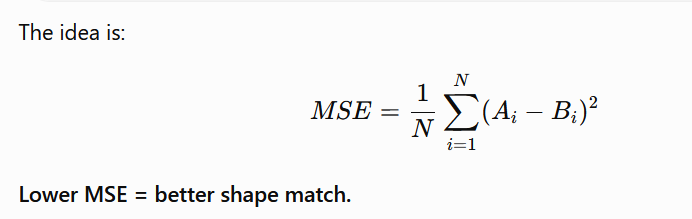

In [276]:
edges_A = split_contour_into_edges(piece_A)
edges_B = split_contour_into_edges(piece_B)

In [277]:
def create_piece_profiles(piece):

    edges = split_contour_into_edges(piece)

    x, y, w, h = cv2.boundingRect(piece)

    piece_center = (
        x + w / 2,
        y + h / 2
    )

    profiles = {}

    for name, edge in edges.items():

        profiles[name] = get_edge_profile(
            edge,
            piece_center,
            name
        )

    return profiles

In [278]:
edge_profiles_A = create_piece_profiles(piece_A)
edge_profiles_B = create_piece_profiles(piece_B)

C:\Users\HP\AppData\Local\Temp\ipykernel_252\1709512756.py:17: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  vx = float(vx)
C:\Users\HP\AppData\Local\Temp\ipykernel_252\1709512756.py:18: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  vy = float(vy)
C:\Users\HP\AppData\Local\Temp\ipykernel_252\1709512756.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  x0 = float(x0)
C:\Users\HP\AppData\Local\Temp\ipykernel_252\1709512756.py:20: DeprecationWarning: Conversion of 

In [279]:
for name in edge_profiles_A:
    print(
        "A",
        name,
        edge_profiles_A[name] is None
    )

for name in edge_profiles_B:
    print(
        "B",
        name,
        edge_profiles_B[name] is None
    )

A Edge 1 False
A Edge 2 False
A Edge 3 False
A Edge 4 False
B Edge 1 False
B Edge 2 False
B Edge 3 False
B Edge 4 False


In [280]:
edge_A = edge_profiles_A["Edge 3"]
edge_B = edge_profiles_B["Edge 1"]

In [281]:
score = compare_edges(
    edge_A,
    "TAB",
    edge_B,
    "GAP"
)

print("Compatibility:", score)

Compatibility: 0.0020290022440396724


In [282]:
score = profile_difference(
    right_A,
    left_B
)

print("Matching MSE:", score)

Matching MSE: 341.36165875799486


Test two edges

Visualise the two matching edges

In [283]:
def plot_edge_match(profile_a, profile_b):

    _, deviation_a = profile_a
    _, deviation_b = profile_b

    deviation_b = -deviation_b[::-1]

    plt.figure(figsize=(10, 5))

    plt.plot(
        deviation_a,
        label="Edge A"
    )

    plt.plot(
        deviation_b,
        label="Edge B (flipped)"
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel("Normalised Position")
    plt.ylabel("Outward Deviation")

    plt.title("Candidate Edge Match")

    plt.legend()
    plt.show()

Add TAB/GAP compatibility

In [284]:
def compatible(edge_type_a, edge_type_b):

    if edge_type_a == "TAB" and edge_type_b == "GAP":
        return True

    if edge_type_a == "GAP" and edge_type_b == "TAB":
        return True

    if edge_type_a == "FLAT" and edge_type_b == "FLAT":
        return True

    return False

Convert MSE into a similarity score

In [285]:
def similarity_from_mse(mse):

    return 1 / (1 + mse)

Create a candidate ranking

Create your first complete matching function

In [286]:
def compare_edges(
    edge_a,
    type_a,
    edge_b,
    type_b
):

    if not compatible(type_a, type_b):
        return None

    mse = profile_difference(
        edge_a,
        edge_b
    )

    if mse is None:
        return None

    similarity = similarity_from_mse(mse)

    return similarity

In [287]:
score = compare_edges(
    edge_A,
    "TAB",
    edge_B,
    "GAP"
)

print("Compatibility:", score)

Compatibility: 0.0020290022440396724


Classify each edge

In [288]:
def classify_edge(profile, flat_threshold=8.0):

    if profile is None:
        return "UNKNOWN"

    position, deviation = profile

    max_positive = np.max(deviation)
    max_negative = np.min(deviation)

    positive_strength = max_positive
    negative_strength = abs(max_negative)

    # Almost straight
    if max(
        positive_strength,
        negative_strength
    ) < flat_threshold:

        return "FLAT"

    # Outward protrusion
    if positive_strength > negative_strength:
        return "TAB"

    # Inward indentation
    return "GAP"

In [289]:
print("PIECE A")

types_A = {}

for name, profile in edge_profiles_A.items():

    edge_type = classify_edge(profile)

    types_A[name] = edge_type

    print(
        f"{name}: {edge_type}"
    )

PIECE A
Edge 1: GAP
Edge 2: GAP
Edge 3: GAP
Edge 4: GAP


In [290]:
print("PIECE B")

types_B = {}

for name, profile in edge_profiles_B.items():

    edge_type = classify_edge(profile)

    types_B[name] = edge_type

    print(
        f"{name}: {edge_type}"
    )

PIECE B
Edge 1: TAB
Edge 2: FLAT
Edge 3: GAP
Edge 4: GAP


In [291]:
def show_edge_types(piece, edge_types, title):

    image = np.zeros(
        (600, 600, 3),
        dtype=np.uint8
    )

    # Draw contour
    cv2.drawContours(
        image,
        [piece],
        -1,
        (255, 255, 255),
        2
    )

    x, y, w, h = cv2.boundingRect(piece)

    labels = [
        ("Edge 1", (x + w // 2, y - 10)),
        ("Edge 2", (x + w + 10, y + h // 2)),
        ("Edge 3", (x + w // 2, y + h + 20)),
        ("Edge 4", (x - 80, y + h // 2))
    ]

    for name, position in labels:

        text = f"{name}: {edge_types[name]}"

        cv2.putText(
            image,
            text,
            position,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 255, 255),
            1
        )

    plt.figure(figsize=(7, 7))

    plt.imshow(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title(title)
    plt.axis("off")
    plt.show()

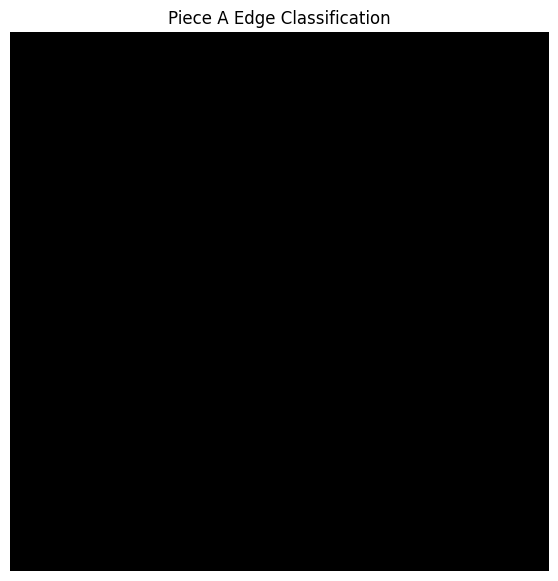

In [292]:
show_edge_types(
    piece_A,
    types_A,
    "Piece A Edge Classification"
)

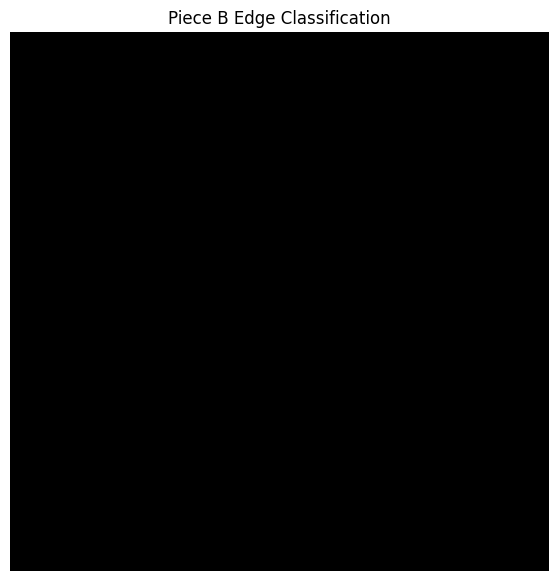

In [293]:
show_edge_types(
    piece_B,
    types_B,
    "Piece B Edge Classification"
)

In [294]:
def compatible(type_a, type_b):

    return (
        (type_a == "TAB" and type_b == "GAP")
        or
        (type_a == "GAP" and type_b == "TAB")
        or
        (type_a == "FLAT" and type_b == "FLAT")
    )

In [295]:
for name_A, type_A in types_A.items():

    for name_B, type_B in types_B.items():

        if compatible(type_A, type_B):

            print(
                name_A,
                type_A,
                "<-->",
                name_B,
                type_B
            )

Edge 1 GAP <--> Edge 1 TAB
Edge 2 GAP <--> Edge 1 TAB
Edge 3 GAP <--> Edge 1 TAB
Edge 4 GAP <--> Edge 1 TAB
